# LEP-18 : Analyser les facteurs socioéconomiques et éducatifs associés à l’espérance de vie

**Projet** : WHO Life Expectancy  
**Sprint** : 4  
**Source des données** : `data/processed/life_expectancy_fiabilise_sanitaire.csv`  
**Période étudiée** : 2000–2015  
**Unité d’observation** : un pays pour une année donnée

## Objectif

Examiner les associations entre les indicateurs socioéconomiques et éducatifs
et l’espérance de vie, puis déterminer si leur sens et leur intensité se
maintiennent au fil des années.

## Question analytique

Quels indicateurs socioéconomiques et éducatifs sont les plus fortement
associés à l’espérance de vie lorsqu’on compare les pays année par année ?

## Démarche

1. Sélectionner les indicateurs et vérifier leurs définitions et leurs unités.
2. Évaluer la qualité des données et la couverture de chaque indicateur par année.
3. Préparer les variables pour l’analyse.
4. Calculer les corrélations annuelles de Spearman et le nombre de pays inclus.
5. Visualiser et interpréter les résultats, puis les exporter pour LEP-19.

Comme dans LEP-17, chaque corrélation sera calculée sur les pays où l’indicateur
et l’espérance de vie sont renseignés pour l’année étudiée. Cette méthode
commune facilitera la comparaison des résultats dans LEP-19.

## 1.Chargement des données et sélection des indicateurs candidats

In [15]:
# Bibliothèques
from zipfile import ZipFile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
# Charger le jeu fiabilisé utilisé dans LEP-17.
df_copy = pd.read_csv("../data/processed/life_expectancy_fiabilise_sanitaire.csv")

# Définir les colonnes à examiner.
colonnes_identification = ["country", "iso3", "year"]
variable_cible = "life_expectancy"
variables_socioeconomiques = [
    "gdp",
    "schooling",
    "income_composition_of_resources",
]

# Créer le tableau de travail pour LEP-18.
colonnes_lep18 = (
    colonnes_identification + [variable_cible] + variables_socioeconomiques
)
df = df_copy.loc[:, colonnes_lep18].copy()

print(f"{df.shape[0]} lignes et {df.shape[1]} colonnes")
display(df.head())

2938 lignes et 7 colonnes


,country,iso3,year,life_expectancy,gdp,schooling,income_composition_of_resources
0,Afghanistan,AFG,2015,62.270,565.569730,10.1,0.479
1,Afghanistan,AFG,2014,62.260,625.054942,10.0,0.476
2,Afghanistan,AFG,2013,62.188,637.087099,9.9,0.470
3,Afghanistan,AFG,2012,61.735,651.417134,9.8,0.463
4,Afghanistan,AFG,2011,61.250,606.694676,9.5,0.454


### 2. Acquisition des données officielles sur le revenu et la scolarisation

Pour l’analyse LEP-18, nous utilisons le fichier
`HDR25_Composite_indices_complete_time_series_pnud.csv`, téléchargé depuis
le portail du Programme des Nations Unies pour le développement (PNUD).

Nous en extrairons, pour la période 2000–2015, le revenu national brut (RNB)
par habitant et le nombre attendu d’années de scolarisation. Ces deux séries
remplaceront respectivement les colonnes `income_composition_of_resources`
et `schooling`, dont les définitions d’origine étaient insuffisamment précisées.

Les séries seront jointes au jeu fiabilisé sanitaire par code pays (`iso3`)
et par année (`year`). Après vérification de leur couverture, le résultat
sera exporté dans `life_expectancy_fiabilise_sanitaire_socioeducatif.csv`.

In [17]:
# Charger le fichier du PNUD.
fichier_pnud = Path(
    "../data/external/HDR25_Composite_indices_complete_time_series_pnud.csv"
)

try:
    pnud_brut = pd.read_csv(fichier_pnud, encoding="utf-8-sig")
except UnicodeDecodeError:
    pnud_brut = pd.read_csv(fichier_pnud, encoding="cp1252")

# Repérer le code pays et les colonnes de revenu et de scolarisation pour 2000.
colonnes_apercu = [
    colonne for colonne in pnud_brut.columns
    if colonne.lower() == "iso3"
    or (
        colonne.lower().startswith(("gni", "eys"))
        and colonne.endswith("_2000")
    )
]

print("Dimensions :", pnud_brut.shape)
print("Colonnes repérées :", colonnes_apercu)
display(pnud_brut[colonnes_apercu].head())

Dimensions : (206, 1112)
Colonnes repérées : ['iso3', 'eys_2000', 'gnipc_2000', 'eys_f_2000', 'gni_pc_f_2000', 'eys_m_2000', 'gni_pc_m_2000']


,iso3,eys_2000,gnipc_2000,eys_f_2000,gni_pc_f_2000,eys_m_2000,gni_pc_m_2000
0,AFG,5.856422,1331.140022,3.825190,NaN,7.521919,NaN
1,ALB,10.821224,6754.124612,10.639982,4549.924086,10.942784,9064.693938
2,DZA,11.221960,11116.297970,11.458746,2159.071156,10.985174,19541.266330
3,AND,10.546596,54809.057050,10.515030,NaN,10.578163,NaN
4,AGO,4.821837,4964.900553,4.306847,NaN,5.339223,NaN


In [18]:
# Préparer les indicateurs du PNUD au format pays–année

# Sélectionner les deux séries sur la période 2000–2015.
annees_etude = range(2000, 2016)
colonnes_pnud = ["iso3"] + [
    f"{indicateur}_{annee}"
    for indicateur in ["gnipc", "eys"]
    for annee in annees_etude
]

# Garder les codes pays présents dans le jeu fiabilisé sanitaire.
pnud_selection = pnud_brut.loc[
    pnud_brut["iso3"].isin(df_copy["iso3"]),
    colonnes_pnud,
].copy()

# Passer à une ligne par pays et par année.
pnud_pays_annee = (
    pd.wide_to_long(
        pnud_selection,
        stubnames=["gnipc", "eys"],
        i="iso3",
        j="year",
        sep="_",
        suffix=r"\d{4}",
    )
    .reset_index()
    .rename(columns={
        "gnipc": "gni_per_capita_ppp_2021",
        "eys": "expected_years_of_schooling",
    })
    .sort_values(["iso3", "year"])
)

display(pnud_pays_annee.head())

# wide_to_long() transforme les colonnes comme eys_2000 et eys_2001 en deux lignes pour le même pays, 
# avec l’année dans la colonne year.


,iso3,year,gni_per_capita_ppp_2021,expected_years_of_schooling
0,AFG,2000,1331.140022,5.856422
191,AFG,2001,1246.158440,6.148418
382,AFG,2002,1946.695886,6.440414
573,AFG,2003,1982.539949,6.732410
764,AFG,2004,1963.734915,7.600430


In [19]:
# Joindre les données du PNUD et vérifier leur couverture

# Ajouter les indicateurs du PNUD en conservant toutes les observations du projet.
df_socioeducatif_comparaison = df_copy.merge(
    pnud_pays_annee,
    on=["iso3", "year"],
    how="left",
    validate="one_to_one",
)

# Vérifier les dimensions après la jointure.
print("Avant la jointure :", df_copy.shape)
print("Après la jointure :", df_socioeducatif_comparaison.shape)

# Mesurer la couverture des deux indicateurs sur les observations du projet.
colonnes_officielles = [
    "gni_per_capita_ppp_2021",
    "expected_years_of_schooling",
]
indicateurs_pnud = df_socioeducatif_comparaison[colonnes_officielles]

couverture_pnud = pd.DataFrame({
    "valeurs_disponibles": indicateurs_pnud.count(),
    "valeurs_manquantes": indicateurs_pnud.isna().sum(),
    "pct_manquant": indicateurs_pnud.isna().mean().mul(100).round(2),
})

display(couverture_pnud)

Avant la jointure : (2938, 23)
Après la jointure : (2938, 25)


,valeurs_disponibles,valeurs_manquantes,pct_manquant
gni_per_capita_ppp_2021,2903,35,1.19
expected_years_of_schooling,2868,70,2.38



La jointure a conservé les 2 938 observations pays–année et ajouté les deux indicateurs du PNUD. Il manque 35 valeurs (1,19 %) pour le RNB par habitant et 70 valeurs (2,38 %) pour les années de scolarisation attendues. On conserve ces valeurs manquantes dans le CSV et on examinera leur répartition par année dans LEP-18.

In [20]:
# Retirer les anciennes colonnes et exporter le CSV

# Retirer les deux colonnes remplacées par les indicateurs du PNUD.
anciennes_colonnes = ["income_composition_of_resources", "schooling"]

df_fiabilise_sanitaire_socioeducatif = (
    df_socioeducatif_comparaison.drop(columns=anciennes_colonnes)
)

# Vérifier que le nouveau jeu conserve les dimensions du jeu sanitaire.
assert df_fiabilise_sanitaire_socioeducatif.shape == df_copy.shape

# Exporter le jeu dans un fichier distinct.
fichier_socioeducatif = Path(
    "../data/processed/life_expectancy_fiabilise_sanitaire_socioeducatif.csv"
)
df_fiabilise_sanitaire_socioeducatif.to_csv(
    fichier_socioeducatif, index=False, encoding="utf-8-sig"
)

print(f"Fichier exporté : {fichier_socioeducatif}")
print(f"Dimensions : {df_fiabilise_sanitaire_socioeducatif.shape}")

Fichier exporté : ..\data\processed\life_expectancy_fiabilise_sanitaire_socioeducatif.csv
Dimensions : (2938, 23)


L’export est confirmé. Le nouveau CSV contient bien 2 938 lignes et 23 colonnes. On peut maintenant reconstruire df pour LEP-18, puis compter les pays disponibles pour chaque corrélation annuelle.

### 3. Préparation du tableau d’analyse et vérification de la couverture annuelle

À partir du jeu fiabilisé enrichi avec les données du PNUD, nous
sélectionnons trois indicateurs pour LEP-18 : le PIB par habitant,
le RNB par habitant et le nombre attendu d’années de scolarisation.

Pour chaque année de 2000 à 2015 et pour chaque indicateur, nous comptons
les pays pour lesquels l’indicateur et l’espérance de vie sont tous deux
renseignés. Comme dans LEP-17, chaque corrélation de Spearman sera calculée
sur ces paires disponibles. Le nombre de pays sera présenté avec le
coefficient pour faciliter l’interprétation et la comparaison des résultats.

In [21]:
# Sélection des indicateurs socioéconomique et couverture par année
# Construire le tableau d'analyse à partir du nouveau jeu fiabilisé.
colonnes_identification = ["country", "iso3", "year"]
variable_cible = "life_expectancy"

variables_socioeconomiques = [
    "gdp",
    "gni_per_capita_ppp_2021",
    "expected_years_of_schooling",
]

colonnes_lep18 = (
    colonnes_identification + [variable_cible] + variables_socioeconomiques
)
df = df_fiabilise_sanitaire_socioeducatif.loc[:, colonnes_lep18].copy()

# Garder les observations où l'espérance de vie est renseignée.
df_cible_disponible = df.dropna(subset=[variable_cible])

# Compter les pays où chaque indicateur est aussi renseigné.
paires_disponibles_par_annee = (
    df_cible_disponible.groupby("year")[variables_socioeconomiques].count()
)

print("Dimensions du tableau d'analyse :", df.shape)
display(paires_disponibles_par_annee)

Dimensions du tableau d'analyse : (2938, 7)


,gdp,gni_per_capita_ppp_2021,expected_years_of_schooling
year,,,
2000,181,180,174
2001,181,180,174
2002,181,180,174
2003,181,180,174
2004,181,180,174
2005,181,180,179
2006,181,180,179
2007,181,180,180
2008,182,182,180


Le tableau confirme une bonne couverture sur les 16 années. Selon l’année, on dispose de 181 à 189 pays pour le PIB par habitant, de 180 à 189 pour le RNB par habitant et de 174 à 190 pour les années de scolarisation attendues. En 2013, les trois indicateurs sont renseignés pour 189 ou 190 des 191 pays dont l’espérance de vie est disponible.

## 4. Etude des associations

### 4.1 Corrélations annuelles de Spearman avec l’espérance de vie

Pour chaque année de 2000 à 2015, nous calculons la corrélation de
Spearman entre l’espérance de vie et chacun des trois indicateurs.
Chaque coefficient compare les rangs des pays d’une même année et
repose sur les pays pour lesquels les deux valeurs sont renseignées.

Les coefficients et les effectifs annuels permettront d’examiner le
sens, la force et la stabilité des associations sur la période.

In [22]:
# Calculer les corrélations de Spearman entre pays, année par année.
correlations_spearman_lep18 = (
    df_cible_disponible
    .groupby("year")[[variable_cible] + variables_socioeconomiques]
    .apply(
        lambda groupe: groupe[variables_socioeconomiques].corrwith(
            groupe[variable_cible],
            method="spearman",
        )
    )
)

display(correlations_spearman_lep18.round(3))

,gdp,gni_per_capita_ppp_2021,expected_years_of_schooling
year,,,
2000,0.858,0.862,0.820
2001,0.861,0.857,0.812
2002,0.859,0.851,0.817
2003,0.847,0.849,0.818
2004,0.845,0.852,0.812
2005,0.834,0.848,0.814
2006,0.832,0.846,0.810
2007,0.841,0.848,0.808
2008,0.849,0.855,0.812


De 2000 à 2015, le PIB par habitant, le RNB par habitant et le nombre
attendu d’années de scolarisation présentent tous une forte corrélation
positive avec l’espérance de vie. Au cours d’une même année, les pays
mieux classés sur ces indicateurs tendent aussi à être mieux classés
selon leur espérance de vie.

Les coefficients annuels de Spearman varient de **0,832 à 0,882** pour le
PIB par habitant, de **0,846 à 0,879** pour le RNB par habitant et de
**0,808 à 0,824** pour les années de scolarisation attendues. La
scolarisation présente la plus faible variation d’une année à l’autre.
Les deux indicateurs économiques affichent des coefficients proches et
leur ordre change selon l’année.

Ces corrélations décrivent des associations entre pays. Elles ne permettent
pas d’isoler la contribution propre de chaque indicateur. La section
suivante visualise les trois séries de coefficients sur une même échelle.

#### 4.2. Évolution des corrélations de 2000 à 2015

Le graphique présente les corrélations annuelles du PIB par habitant,
du RNB par habitant et des années de scolarisation attendues avec
l’espérance de vie. Il permet de comparer leur stabilité sur la période
et de repérer les années où le PIB et le RNB changent de rang.
Chaque point représente une comparaison entre pays pour une même année.

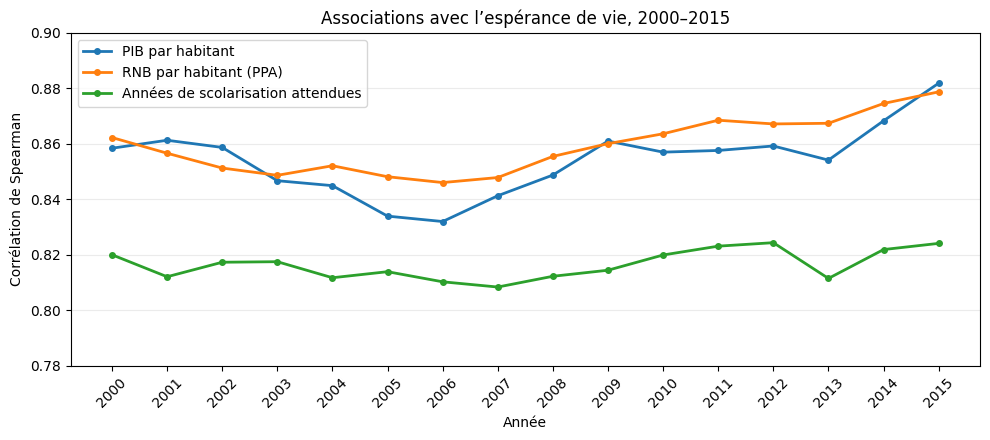

In [23]:
# Donner des libellés lisibles aux trois indicateurs.
libelles_lep18 = {
    "gdp": "PIB par habitant",
    "gni_per_capita_ppp_2021": "RNB par habitant (PPA)",
    "expected_years_of_schooling": "Années de scolarisation attendues",
}

correlations_a_tracer = correlations_spearman_lep18.rename(columns=libelles_lep18)

# Tracer les corrélations annuelles sur une même échelle.
fig, ax = plt.subplots(figsize=(10, 4.5))
correlations_a_tracer.plot(ax=ax, marker="o", linewidth=2, markersize=4)

ax.set_title("Associations avec l’espérance de vie, 2000–2015")
ax.set_xlabel("Année")
ax.set_ylabel("Corrélation de Spearman")
ax.set_xticks(range(2000, 2016))
ax.set_ylim(0.78, 0.90)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper left")

fig.tight_layout()
plt.show()

# L’axe vertical est limité à 0,78–0,90 pour rendre visibles les écarts entre des coefficients proches.

Le graphique montre que les corrélations du PIB et du RNB par habitant restent proches et se croisent à plusieurs reprises. La scolarisation présente la corrélation la plus stable, avec des coefficients entre 0,808 et 0,824.

### 4.3. Comparer le PIB et le RNB sur les mêmes pays

Pour chaque année, nous recalculons les corrélations du PIB et du RNB par
habitant avec l’espérance de vie sur les mêmes pays. Nous retenons les pays
pour lesquels les trois valeurs sont disponibles. En comparant ces résultats
aux coefficients initiaux, nous vérifions si les écarts et les changements
de classement persistent lorsque les deux calculs portent sur le même groupe.
Ce groupe peut varier d’une année à l’autre.

In [24]:
# Garder les pays où le PIB, le RNB et l'espérance de vie sont renseignés.
indicateurs_economiques = ["gdp", "gni_per_capita_ppp_2021"]
colonnes_comparaison = [variable_cible] + indicateurs_economiques

df_pays_communs_economie = df_cible_disponible.dropna(
    subset=colonnes_comparaison
)

# Calculer les deux corrélations sur le même groupe de pays chaque année.
groupes_annuels = df_pays_communs_economie.groupby("year")

comparaison_economique = (
    groupes_annuels[colonnes_comparaison]
    .apply(
        lambda groupe: groupe[indicateurs_economiques].corrwith(
            groupe[variable_cible], method="spearman"
        )
    )
    .rename(columns={
        "gdp": "spearman_pib",
        "gni_per_capita_ppp_2021": "spearman_rnb",
    })
)

# Comparer les écarts avant et après restriction aux mêmes pays.
comparaison_economique["nb_pays_communs"] = groupes_annuels.size()
comparaison_economique["ecart_initial_rnb_moins_pib"] = (
    correlations_spearman_lep18["gni_per_capita_ppp_2021"]
    - correlations_spearman_lep18["gdp"]
)
comparaison_economique["ecart_pays_communs_rnb_moins_pib"] = (
    comparaison_economique["spearman_rnb"]
    - comparaison_economique["spearman_pib"]
)

display(comparaison_economique.round(3))

,spearman_pib,spearman_rnb,nb_pays_communs,ecart_initial_rnb_moins_pib,ecart_pays_communs_rnb_moins_pib
year,,,,,
2000,0.858,0.862,180,0.004,0.004
2001,0.861,0.857,180,-0.005,-0.005
2002,0.859,0.851,180,-0.007,-0.007
2003,0.847,0.849,180,0.002,0.002
2004,0.845,0.852,180,0.007,0.007
2005,0.834,0.848,180,0.014,0.014
2006,0.832,0.846,180,0.014,0.014
2007,0.841,0.848,180,0.007,0.007
2008,0.849,0.855,182,0.007,0.007


#### Interprétation de la comparaison sur les mêmes pays

Selon l’année, la comparaison porte sur 180 à 188 pays pour lesquels
le PIB par habitant, le RNB par habitant et l’espérance de vie sont
tous renseignés. Le RNB présente la corrélation la plus élevée dans
12 années sur 16. Le classement reste le même qu’avec les paires
disponibles pour chaque indicateur.

Les écarts restent faibles. En 2013, l’écart en faveur du RNB passe
de 0,013 à 0,016 lorsqu’on utilise les mêmes pays. Les deux indicateurs
économiques présentent donc des associations de force comparable avec
l’espérance de vie sur la période étudiée.

#### 4.4. Synthèse des associations sur la période 2000–2015

Pour chaque indicateur, nous résumons les 16 corrélations annuelles de
Spearman par leur médiane, leur minimum et leur maximum. Nous indiquons
aussi le plus petit et le plus grand nombre de pays inclus par année.

Les indicateurs sont classés selon la valeur absolue de leur corrélation
médiane, comme dans LEP-17. Ce classement décrit la force des associations
observées et servira à la comparaison dans LEP-19.

In [25]:
# Résumer les coefficients annuels pour chaque indicateur.
synthese_lep18 = (
    correlations_spearman_lep18.agg(["median", "min", "max"]).T
    .rename(columns={
        "median": "spearman_median",
        "min": "spearman_min",
        "max": "spearman_max",
    })
)

# Ajouter les effectifs annuels minimum et maximum.
synthese_lep18["pays_min"] = paires_disponibles_par_annee.min()
synthese_lep18["pays_max"] = paires_disponibles_par_annee.max()

# Classer les indicateurs selon la force de leur association médiane.
synthese_lep18 = synthese_lep18.sort_values(
    "spearman_median",
    key=lambda coefficients: coefficients.abs(),
    ascending=False,
)

display(synthese_lep18.round(3))

,spearman_median,spearman_min,spearman_max,pays_min,pays_max
gni_per_capita_ppp_2021,0.858,0.846,0.879,180,189
gdp,0.857,0.832,0.882,181,189
expected_years_of_schooling,0.816,0.808,0.824,174,190


#### 4.5. Corrélation médiane et variation annuelle par indicateur

Pour chaque indicateur, le point représente la médiane des 16 corrélations
annuelles de Spearman. Le segment relie le minimum et le maximum observés
entre 2000 et 2015. L’axe horizontal est limité à 0,78–0,90 pour rendre
visibles les écarts entre les trois indicateurs.

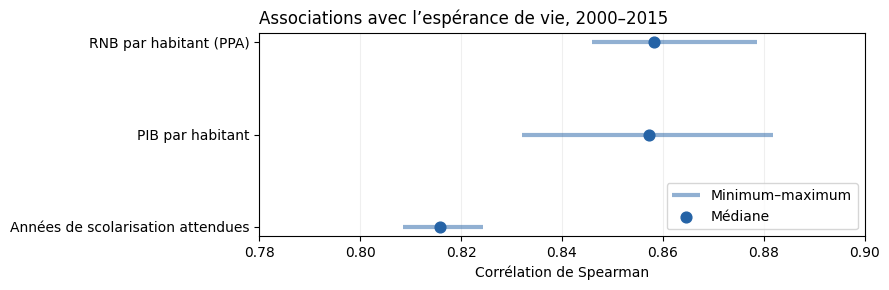

In [26]:
import matplotlib.pyplot as plt

# Reprendre les libellés et l'ordre du tableau de synthèse.
graphique_lep18 = synthese_lep18.rename(index=libelles_lep18)
positions = range(len(graphique_lep18))

fig, ax = plt.subplots(figsize=(9, 3))

# Tracer les plages annuelles et les médianes.
ax.hlines(
    y=positions,
    xmin=graphique_lep18["spearman_min"],
    xmax=graphique_lep18["spearman_max"],
    color="#2563A6",
    linewidth=3,
    alpha=0.5,
    label="Minimum–maximum",
)
ax.scatter(
    graphique_lep18["spearman_median"],
    positions,
    color="#2563A6",
    s=60,
    zorder=3,
    label="Médiane",
)

ax.set_yticks(list(positions))
ax.set_yticklabels(graphique_lep18.index)
ax.invert_yaxis()
ax.set_xlim(0.78, 0.90)
ax.set_xlabel("Corrélation de Spearman")
ax.set_title("Associations avec l’espérance de vie, 2000–2015", loc="left")
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="lower right")

fig.tight_layout()
plt.show()

Le graphique montre que le PIB et le RNB par habitant ont des corrélations médianes presque identiques, mais que celle du PIB varie davantage selon l’année. La scolarisation a le segment le plus court, de 0,808 à 0,824. Ces segments représentent les valeurs annuelles observées.

5. Exportation des corrélations annuelles et des effectifs

In [27]:
# Mettre les coefficients et les effectifs au format long.
coefficients_lep18 = correlations_spearman_lep18.reset_index().melt(
    id_vars="year",
    var_name="indicateur",
    value_name="spearman",
)

effectifs_lep18 = paires_disponibles_par_annee.reset_index().melt(
    id_vars="year",
    var_name="indicateur",
    value_name="nb_pays",
)

# Associer chaque coefficient à son effectif.
resultats_lep18 = coefficients_lep18.merge(
    effectifs_lep18,
    on=["year", "indicateur"],
    how="left",
    validate="one_to_one",
).sort_values(["year", "indicateur"])

# Exporter les coefficients sans les arrondir.
fichier_resultats = Path("../reports/tables/lep18_correlations_annuelles.csv")
fichier_resultats.parent.mkdir(parents=True, exist_ok=True)
resultats_lep18.to_csv(fichier_resultats, index=False, encoding="utf-8-sig")

print(f"{len(resultats_lep18)} lignes exportées vers {fichier_resultats}")

48 lignes exportées vers ..\reports\tables\lep18_correlations_annuelles.csv


### 6. Conclusion de LEP-18

De 2000 à 2015, les trois indicateurs présentent des associations fortes
et positives avec l’espérance de vie. Chaque année, les pays qui se
classent plus haut pour le revenu, la production économique ou la
scolarisation tendent aussi à se classer plus haut pour l’espérance de vie.

Le RNB par habitant et le PIB par habitant présentent des corrélations
médianes presque identiques (**0,858** et **0,857**). Le recalcul sur les
mêmes pays pour chaque année confirme que leurs associations sont de
force comparable.

Les années de scolarisation attendues présentent une corrélation médiane
de **0,816**. Leur coefficient varie de **0,808 à 0,824**, ce qui en fait
l’association la plus stable des trois sur la période.

Ces résultats décrivent des associations entre pays. Ils ne permettent
pas d’isoler la contribution propre de chaque indicateur à l’espérance
de vie ni d’établir une relation causale.